In [1]:
# Step 1: Import required libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as shc

from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score

In [3]:
# Step 2: Load the dataset

In [4]:
X = pd.read_csv("/home/anurag/Codes_7th_Sem/IR/IRDataset/Assign5/CC_GENERAL.csv")

In [5]:
print("Dataset Shape:", X.shape)
print("\nFirst 5 Records:")
print(X.head())

Dataset Shape: (8950, 18)

First 5 Records:
  CUST_ID      BALANCE  BALANCE_FREQUENCY  PURCHASES  ONEOFF_PURCHASES  \
0  C10001    40.900749           0.818182      95.40              0.00   
1  C10002  3202.467416           0.909091       0.00              0.00   
2  C10003  2495.148862           1.000000     773.17            773.17   
3  C10004  1666.670542           0.636364    1499.00           1499.00   
4  C10005   817.714335           1.000000      16.00             16.00   

   INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  \
0                    95.4      0.000000             0.166667   
1                     0.0   6442.945483             0.000000   
2                     0.0      0.000000             1.000000   
3                     0.0    205.788017             0.083333   
4                     0.0      0.000000             0.083333   

   ONEOFF_PURCHASES_FREQUENCY  PURCHASES_INSTALLMENTS_FREQUENCY  \
0                    0.000000                          0.08

In [6]:
# Step 3: Remove customer ID

In [7]:
X = X.drop(columns=["CUST_ID"], errors="ignore")

In [8]:
# Step 4: Convert data to numeric and handle missing values

In [9]:
X = X.apply(pd.to_numeric, errors="coerce")
X = X.replace([np.inf, -np.inf], np.nan)

imputer = SimpleImputer(strategy="median")
X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

print("\nMissing Values After Cleaning:",
      X.isnull().sum().sum())


Missing Values After Cleaning: 0


In [10]:
# Step 5: Standardize the data

In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [12]:
# Step 6: Normalize the standardized data

In [13]:
X_normalized = normalize(X_scaled)

In [14]:
# Step 7: Apply PCA for dimensionality reduction

In [15]:
pca = PCA(n_components=2, random_state=42)
X_principal = pca.fit_transform(X_normalized)

X_principal = pd.DataFrame(
    X_principal,
    columns=["P1", "P2"]
)

print("\nPCA Data:")
print(X_principal.head())

print("\nTotal Explained Variance Ratio:",
      round(pca.explained_variance_ratio_.sum(), 4))


PCA Data:
         P1        P2
0 -0.490443 -0.679237
1 -0.518542  0.545284
2  0.330939  0.269024
3 -0.479448 -0.105320
4 -0.563829 -0.480941

Total Explained Variance Ratio: 0.4745


In [16]:
# Step 8: Draw the dendrogram

In [17]:
print("\nTotal Explained Variance Ratio:",
      pca.explained_variance_ratio_.sum())


Total Explained Variance Ratio: 0.47448732887830547


In [18]:
# Step 5: Draw a dendrogram using a sample
# A sample keeps the dendrogram computation manageable.

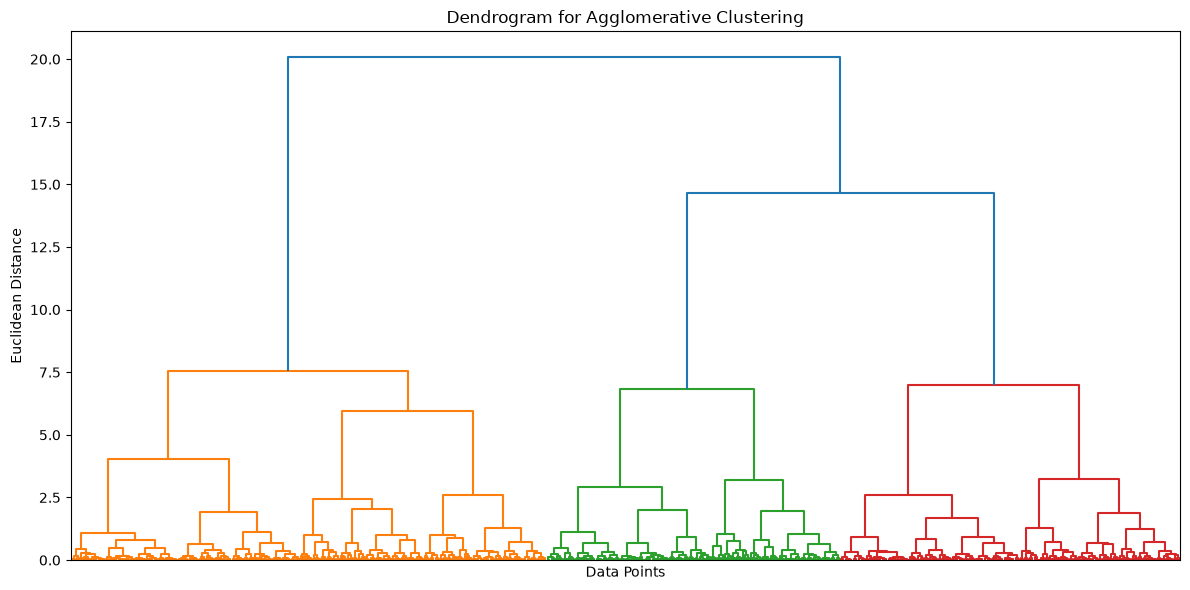

In [17]:
# Use a sample to keep computation manageable

sample_size = min(1000, len(X_principal))

X_sample = X_principal.sample(
    n=sample_size,
    random_state=42
)

plt.figure(figsize=(12, 6))

shc.dendrogram(
    shc.linkage(X_sample, method="ward"),
    no_labels=True
)

plt.title("Dendrogram for Agglomerative Clustering")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()

In [18]:
# Step 9: Prepare a consistent sample for clustering

In [19]:
cluster_size = min(3000, len(X_principal))

X_cluster = X_principal.sample(
    n=cluster_size,
    random_state=42
).reset_index(drop=True)

print("\nNumber of records used for clustering:",
      len(X_cluster))


Number of records used for clustering: 3000


In [20]:
# Step 10: Apply Agglomerative Clustering for k = 2 to 6


Number of Clusters (k) = 2
Cluster Sizes:
0    1687
1    1313
Name: count, dtype: int64
Silhouette Score: 0.4255


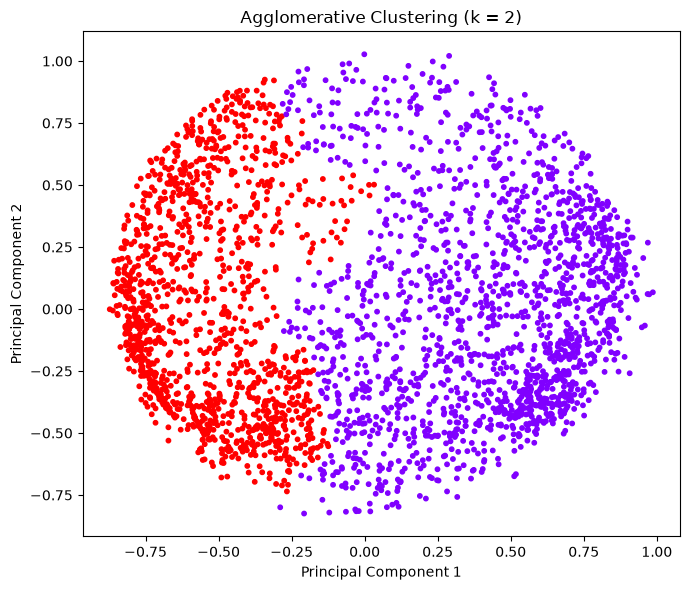


Number of Clusters (k) = 3
Cluster Sizes:
0    1313
1    1031
2     656
Name: count, dtype: int64
Silhouette Score: 0.3568


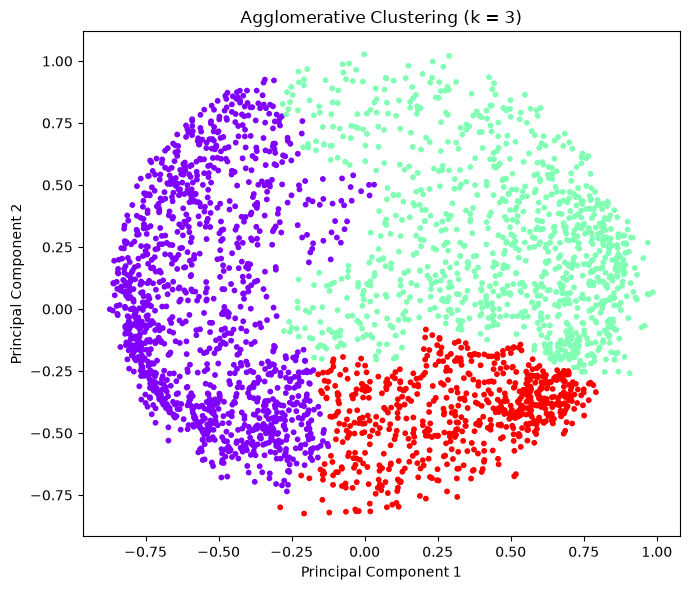


Number of Clusters (k) = 4
Cluster Sizes:
0    1031
1     947
2     656
3     366
Name: count, dtype: int64
Silhouette Score: 0.3517


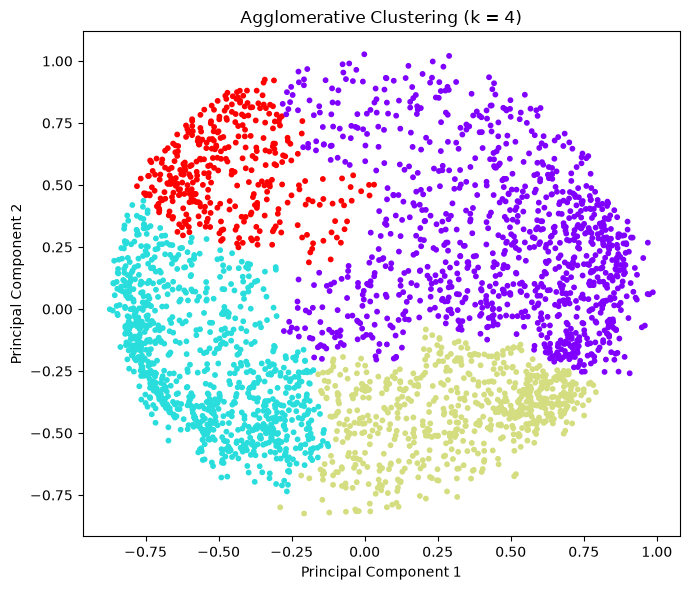


Number of Clusters (k) = 5
Cluster Sizes:
0    947
1    509
2    656
3    366
4    522
Name: count, dtype: int64
Silhouette Score: 0.3576


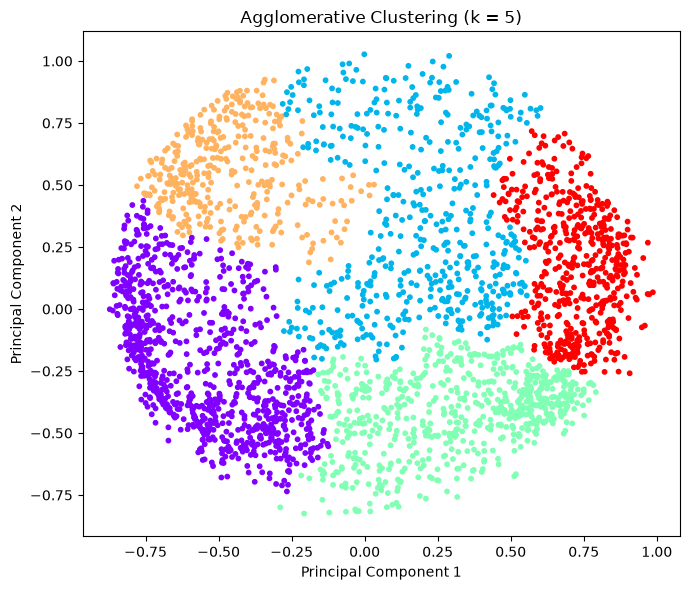


Number of Clusters (k) = 6
Cluster Sizes:
0    509
1    522
2    656
3    366
4    529
5    418
Name: count, dtype: int64
Silhouette Score: 0.3436


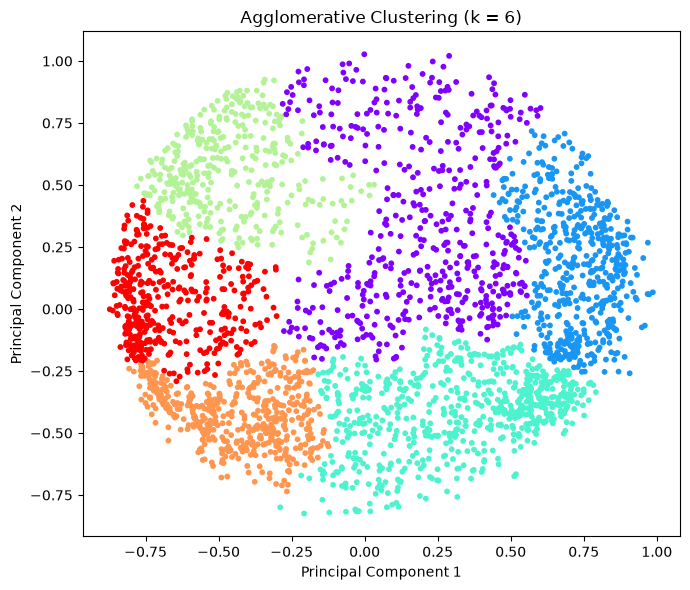

In [21]:
k_values = [2, 3, 4, 5, 6]
silhouette_scores = []

for k in k_values:

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = model.fit_predict(X_cluster)

    # Calculate silhouette score
    score = silhouette_score(X_cluster, labels)
    silhouette_scores.append(score)

    # Display cluster information
    print(f"\nNumber of Clusters (k) = {k}")

    print("Cluster Sizes:")
    print(
        pd.Series(labels)
        .value_counts()
        .sort_index()
    )

    print("Silhouette Score:", round(score, 4))

    # Visualize clusters
    plt.figure(figsize=(7, 6))

    plt.scatter(
        X_cluster["P1"],
        X_cluster["P2"],
        c=labels,
        cmap="rainbow",
        s=10
    )

    plt.title(
        f"Agglomerative Clustering (k = {k})"
    )
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.tight_layout()
    plt.show()


In [22]:
# Step 11: Compare silhouette scores

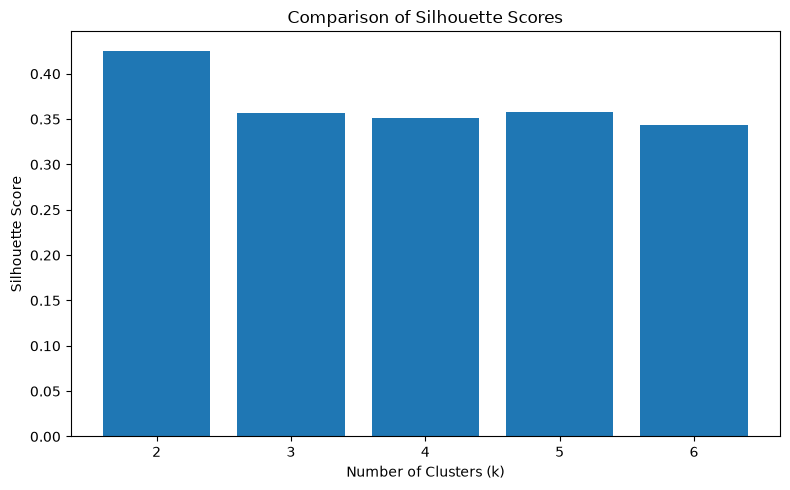

In [23]:
plt.figure(figsize=(8, 5))

plt.bar(k_values, silhouette_scores)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Comparison of Silhouette Scores")
plt.xticks(k_values)
plt.tight_layout()
plt.show()

In [24]:
# Step 12: Identify the best k using silhouette score

In [25]:
best_index = np.argmax(silhouette_scores)
best_k = k_values[best_index]
best_score = silhouette_scores[best_index]

print("\nSilhouette Score Comparison:")

for k, score in zip(k_values, silhouette_scores):
    print(f"k = {k}: {score:.4f}")

print("\nBest Number of Clusters:", best_k)
print("Best Silhouette Score:", round(best_score, 4))


Silhouette Score Comparison:
k = 2: 0.4255
k = 3: 0.3568
k = 4: 0.3517
k = 5: 0.3576
k = 6: 0.3436

Best Number of Clusters: 2
Best Silhouette Score: 0.4255
